
=== ROUND-1 ATTACKS ===

Digit: 0
Digit: 1
Digit: 2
Digit: 3
Digit: 4
Digit: 5
Digit: 6
Digit: 7
Digit: 8
Digit: 9


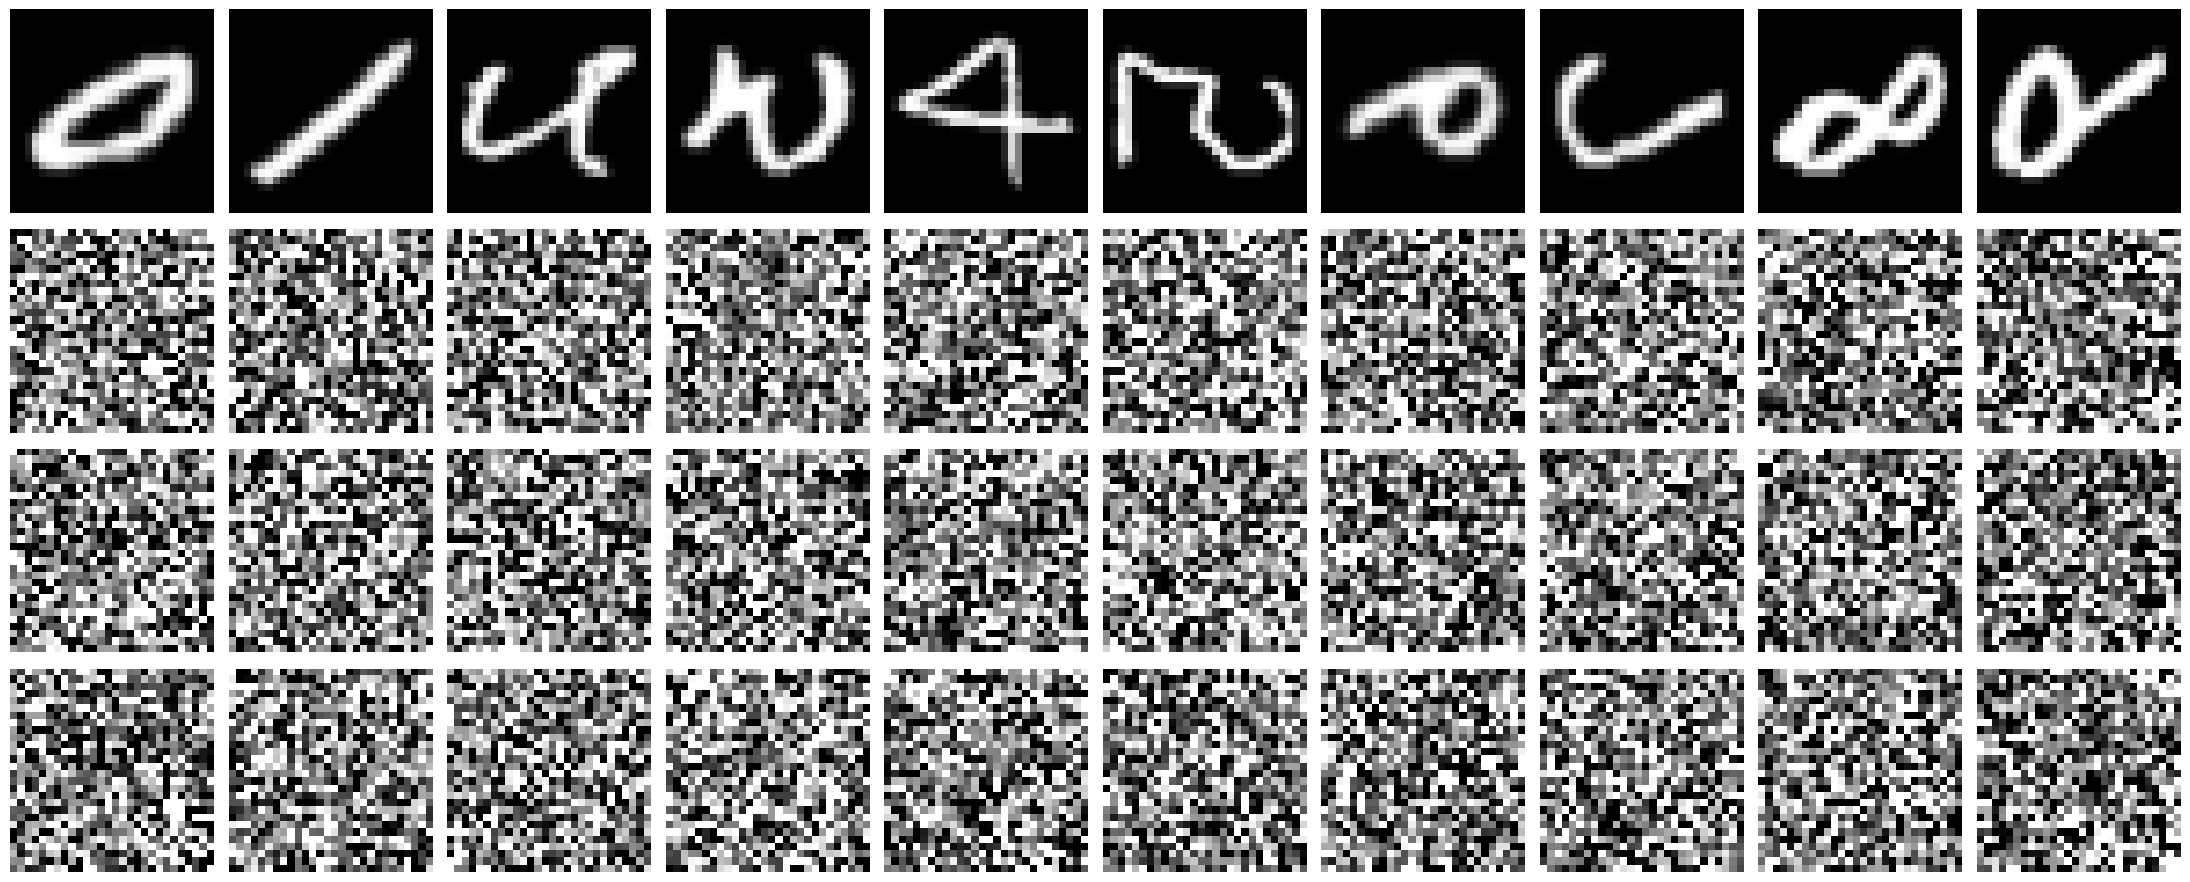

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Saved: _digits_fpman1_all_attacks.png


In [ ]:
# ==============================
# FL ROUND-1 + MASKING + NOISE + ALL ATTACKS
# ==============================

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import random
import copy
import matplotlib.pyplot as plt
from google.colab import files

# -------------------------
# CONFIG
# -------------------------
NUM_CLIENTS = 100
CLIENT_FRAC = 0.3
LOCAL_EPOCHS = 3
BATCH_SIZE = 128
LR = 0.01
MASK_SCALE = 0.001
ADAPTIVE_NOISE_FACTOR = 0.1
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# -------------------------
# DATA
# -------------------------
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.EMNIST(
    root="./data",
    split="digits",
    train=True,
    download=True,
    transform=transform
)

targets = np.array(train_dataset.targets)

# -------------------------
# MODEL
# -------------------------
class EMNIST_CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(64 * 7 * 7, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

# -------------------------
# HELPERS
# -------------------------
def model_to_vector(model):
    return torch.cat([p.data.view(-1) for p in model.parameters()])

def vector_to_model(model, vec):
    ptr = 0
    for p in model.parameters():
        n = p.numel()
        p.data = vec[ptr:ptr+n].view_as(p).clone()
        ptr += n

def norm_img(x):
    x = x - x.min()
    x = x / (x.max() + 1e-8)
    return x

# -------------------------
# DATA SPLIT
# -------------------------
client_data = {i: [] for i in range(NUM_CLIENTS)}

for c in range(10):
    idx = np.where(targets == c)[0]
    np.random.shuffle(idx)
    split = np.array_split(idx, NUM_CLIENTS)
    for i in range(NUM_CLIENTS):
        client_data[i].extend(split[i])

# -------------------------
# GLOBAL MODEL
# -------------------------
global_model = EMNIST_CNN().to(DEVICE)
global_vec = model_to_vector(global_model)

# -------------------------
# CLIENTS
# -------------------------
selected_clients = random.sample(range(NUM_CLIENTS), int(NUM_CLIENTS * CLIENT_FRAC))

# -------------------------
# MASKING
# -------------------------
masks = {cid: torch.zeros_like(global_vec) for cid in selected_clients}
sorted_ids = sorted(selected_clients)

for i, cid in enumerate(sorted_ids):
    right = sorted_ids[(i + 1) % len(sorted_ids)]
    if cid < right:
        m = torch.randn_like(global_vec) * MASK_SCALE
        masks[cid] += m
        masks[right] -= m

# -------------------------
# STORE
# -------------------------
updates = []
labels = []
digit_samples = {}

for img, y in train_dataset:
    y = int(y)
    if y not in digit_samples:
        digit_samples[y] = img
    if len(digit_samples) == 10:
        break

# =====================================================
# ROUND 1 TRAINING
# =====================================================
for cid in selected_clients:

    local_model = copy.deepcopy(global_model)
    local_model.train()

    opt = optim.SGD(local_model.parameters(), lr=LR, momentum=0.9)

    loader = DataLoader(
        Subset(train_dataset, client_data[cid]),
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    for _ in range(LOCAL_EPOCHS):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            loss = F.cross_entropy(local_model(x), y)
            loss.backward()
            opt.step()

    delta = model_to_vector(local_model) - global_vec

    # noise
    noise = torch.randn_like(delta) * delta.norm() * ADAPTIVE_NOISE_FACTOR
    delta += noise

    # mask
    delta += masks[cid]

    updates.append(delta.detach().clone())

    client_labels = targets[client_data[cid]]
    labels.append(np.bincount(client_labels).argmax())

# =====================================================
# ATTACK 1: DLG (simple reconstruction)
# =====================================================
def dlg_attack(update, label):

    model = copy.deepcopy(global_model).to(DEVICE)
    vector_to_model(model, global_vec + update)

    x = torch.randn(1, 1, 28, 28, device=DEVICE, requires_grad=True)
    opt = optim.Adam([x], lr=0.1)

    y = torch.tensor([label]).to(DEVICE)

    for _ in range(200):
        opt.zero_grad()
        loss = F.cross_entropy(model(x), y)
        loss.backward()
        opt.step()
        x.data.clamp_(-1, 1)

    return x.detach()

# =====================================================
# ATTACK 2: iDLG (label search)
# =====================================================
def idlg_attack(update):

    best_img = None
    best_loss = 1e9

    for label in range(10):

        model = copy.deepcopy(global_model).to(DEVICE)
        vector_to_model(model, global_vec + update)

        x = torch.randn(1, 1, 28, 28, device=DEVICE, requires_grad=True)
        opt = optim.Adam([x], lr=0.1)

        y = torch.tensor([label]).to(DEVICE)

        for _ in range(100):
            opt.zero_grad()
            loss = F.cross_entropy(model(x), y)
            loss.backward()
            opt.step()
            x.data.clamp_(-1, 1)

        if loss.item() < best_loss:
            best_loss = loss.item()
            best_img = x.detach()

    return best_img

# =====================================================
# ATTACK 3: GradInv
# =====================================================
def gradinv_attack(update, label):

    model = copy.deepcopy(global_model).to(DEVICE)
    vector_to_model(model, global_vec + update)

    x = torch.randn(1, 1, 28, 28, device=DEVICE, requires_grad=True)
    opt = optim.Adam([x], lr=0.1)

    y = torch.tensor([label]).to(DEVICE)

    for _ in range(200):
        opt.zero_grad()
        loss = F.cross_entropy(model(x), y)
        loss.backward()
        opt.step()
        x.data.clamp_(-1, 1)

    return x.detach()

# =====================================================
# RUN ATTACKS
# =====================================================
print("\n=== ROUND-1 ATTACKS ===\n")

orig, dlg, idlg, gi = [], [], [], []

for i in range(10):

    update = updates[i]
    label = labels[i]

    print("Digit:", i)

    orig.append(digit_samples[i].squeeze().cpu().numpy())
    dlg.append(dlg_attack(update, label).squeeze().cpu().numpy())
    idlg.append(idlg_attack(update).squeeze().cpu().numpy())
    gi.append(gradinv_attack(update, label).squeeze().cpu().numpy())

# =====================================================
# VISUALIZATION
# =====================================================
fig, axes = plt.subplots(4, 10, figsize=(22, 9))

for i in range(10):

    axes[0, i].imshow(norm_img(orig[i]), cmap="gray")
    axes[1, i].imshow(norm_img(dlg[i]), cmap="gray")
    axes[2, i].imshow(norm_img(idlg[i]), cmap="gray")
    axes[3, i].imshow(norm_img(gi[i]), cmap="gray")

    for j in range(4):
        axes[j, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("DLG")
axes[2, 0].set_ylabel("iDLG")
axes[3, 0].set_ylabel("GradInv")

plt.tight_layout()

# =====================================================
# SAVE + DOWNLOAD
# =====================================================
SAVE_PATH = "emnist_digits_fpman1_all_attacks.png"
plt.savefig(SAVE_PATH, dpi=300, bbox_inches="tight")
plt.show()

files.download(SAVE_PATH)

print("\nSaved:", SAVE_PATH)

In [2]:
# =====================================================
# SAVE SEPARATE IMAGE ROWS
# =====================================================

from google.colab import files

# -------------------------
# helper function
# -------------------------
def save_row(images, filename):

    fig, axes = plt.subplots(1, 10, figsize=(20, 2))

    for i in range(10):
        axes[i].imshow(images[i], cmap="gray")
        axes[i].axis("off")

    plt.subplots_adjust(
        left=0,
        right=1,
        top=1,
        bottom=0,
        wspace=0.12,
        hspace=0
    )

    plt.savefig(filename, dpi=300, bbox_inches="tight", pad_inches=0)
    plt.close()

# =====================================================
# BUILD ROW LISTS FROM YOUR ATTACK OUTPUTS
# (from the main code)
# =====================================================

original_results = orig
dlg_results = dlg
idlg_results = idlg
gi_results = gi

# =====================================================
# SAVE 4 ROW IMAGES
# =====================================================

save_row(original_results, "emnist_digits_fpman1_original_row.png")
save_row(dlg_results, "emnist_digits_fpman1_dlg_row.png")
save_row(idlg_results, "emnist_digits_fpman1_idlg_row.png")
save_row(gi_results, "emnist_digits_fpman1_gradinv_row.png")

print("\nALL ROW IMAGES SAVED\n")

# =====================================================
# DOWNLOAD
# =====================================================

files.download("emnist_digits_fpman1_original_row.png")
files.download("emnist_digits_fpman1_dlg_row.png")
files.download("emnist_digits_fpman1_idlg_row.png")
files.download("emnist_digits_fpman1_gradinv_row.png")


ALL ROW IMAGES SAVED



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>